# DBMS Fundamentals: Indexing, B-Trees and Hashing

> **Who is this for?** Learners who finished `01_Python/01_basic.ipynb` and the previous notebook, and want to know *how* a database finds
> one row among millions in a handful of disk reads. It is also exam/interview revision for the indexing chapter of a DBMS course.
>
> **What you will learn**
> - Why indexes exist and how to reason about cost in **block reads**
> - Index vocabulary: **primary/clustering vs. secondary**, **clustered vs. non-clustered**, **dense vs. sparse**, **single- vs. multi-level**
> - **B-trees vs. B+ trees**, and a **B+ tree built from scratch**: insert with node splits, search, range queries over linked leaves,
>   delete with borrow/merge, drawings of the tree, and the formulas for order (fan-out) and height
> - **Hash indexes**: static hashing with overflow chains, **extendible hashing** (implemented), **linear hashing** (briefly)
> - **Bitmap indexes** (implemented, with AND/OR/NOT) and **inverted indexes** (implemented, with BM25 ranking)
> - Real indexes in **SQLite**: `CREATE INDEX`, covering indexes, clustered (`WITHOUT ROWID`) tables, `EXPLAIN QUERY PLAN`, timings on 200,000 rows
> - When indexes **hurt**: write cost and low selectivity
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb), [`../01_sql/01_sql_fundamentals.ipynb`](../01_sql/01_sql_fundamentals.ipynb),
> and [`06_recovery_and_storage.ipynb`](06_recovery_and_storage.ipynb) (blocks, files, the cost of a heap/sorted/hashed file).
>
> **Time needed:** about 3 hours (the code runs in about a minute).
>
> **Runs on:** CPU only, no API key, no internet. Python standard library, numpy, pandas, matplotlib.
>
> **Optional track:** part of the *university-level fundamentals track*; recommended for BS/MS AI students and interview prep.

### Contents
1. Why indexes? The cost model
2. Index types: primary/clustered vs. secondary, dense vs. sparse, multi-level
3. B-trees vs. B+ trees, and a B+ tree from scratch
4. Order, fan-out and height: the exam formulas
5. Hash-based indexing: static, extendible, linear hashing
6. Bitmap indexes
7. Inverted indexes and BM25
8. Indexes in SQLite: EXPLAIN QUERY PLAN, covering and clustered indexes
9. When indexes hurt
10. How this connects to modern AI (and vector indexes)
11. Recap, practice problems, further reading

## Explained simply

A table can have millions of rows, and reading all of them to find one is slow.
An **index** is a small, sorted helper structure that tells the database exactly where to look, like the index at the back of a textbook.
The most common index is the **B+ tree**: a very short, very wide tree, so even a billion rows need only 3 or 4 steps to find one.
Other indexes suit other questions: **hash** indexes for exact matches, **bitmaps** for columns with few values, **inverted** indexes for searching text.
Indexes are not free: every time you add or change a row, every index must be updated too.

- **Everyday example 1:** a dictionary. You do not read it from page 1; the alphabetical order lets you jump straight to the right page.
- **Everyday example 2:** a cloakroom ticket. Ticket 37 means hook 37: no searching at all (that is a hash index).
- **Everyday example 3:** a library catalogue that lists, for every topic word, the shelves holding books about it (an inverted index, like a search engine).

**Tiny example.** 1,000,000 student records stored 100 per page = 10,000 pages. Reading page by page to find one roll number takes about
5,000 page reads on average. A B+ tree whose pages hold 100 keys each needs 3 levels (100 × 100 × 100 = 1,000,000), so the same lookup takes about **4 reads**.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| B+ tree index | a sorted, very wide tree that finds any key in a few steps | every SQL database; feature stores looking up a user's features |
| Hash index | key → bucket number → one step | dictionaries in Python, caches, key-value stores |
| Inverted index | for every word, the list of documents containing it | Google-style search, BM25 keyword search in RAG chatbots |

In [1]:
import bisect, math, random, re, time, sqlite3
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

random.seed(0); np.random.seed(0)
pd.set_option('display.width', 140)
print('sqlite', sqlite3.sqlite_version)

sqlite 3.45.1


---
## 1. Why indexes? The cost model

> **In plain English:** an index is like the index at the back of a book: a small sorted list that tells you where to look, so you do not read every page.

**Analogy.** To find "B+ tree" in a 900-page textbook you do not read every page: you open the **index at the back**, which is
sorted, small, and tells you the page number. A database index is the same: a small, sorted (or hashed) structure that maps a
**search key** to the location (**record id**, RID) of the rows.

Since a disk/SSD read is thousands of times slower than a memory access (notebook 06), we measure cost as **the number of blocks read**.
Notation (Elmasri & Navathe): r records, record size R, block size B, **blocking factor bfr = ⌊B/R⌋**, file size **b = ⌈r / bfr⌉** blocks.

Elmasri's classic example: r = 300,000 records of R = 100 bytes, B = 4,096 bytes. An index entry is a 9-byte key plus a 6-byte block pointer.

In [2]:
r, R, B = 300_000, 100, 4096
bfr = B // R                                   # records per block
b = math.ceil(r / bfr)                         # blocks in the data file
entry = 9 + 6                                  # index entry = key (9 B) + block pointer (6 B)
bfr_i = B // entry                             # index entries per block = the index FAN-OUT
b_i = math.ceil(b / bfr_i)                     # sparse primary index: one entry per data block
levels = math.ceil(math.log(b, bfr_i))         # multi-level index: levels until one block remains

rows = [
    ('linear scan, key not ordered (average)', b // 2,                       'b/2'),
    ('linear scan, key not ordered (worst / not found)', b,                  'b'),
    ('binary search, file sorted on the key', math.ceil(math.log2(b)),       'ceil(log2 b)'),
    ('primary (sparse) index + binary search on it', math.ceil(math.log2(b_i)) + 1, 'ceil(log2 b_i) + 1'),
    ('multi-level index (or B+ tree)', levels + 1,                           'levels + 1'),
]
print(f'bfr = {bfr} records/block, b = {b} data blocks, index fan-out = {bfr_i}, index blocks b_i = {b_i}, levels = {levels}')
print(pd.DataFrame(rows, columns=['access method', 'block reads', 'formula']).to_string(index=False))

bfr = 40 records/block, b = 7500 data blocks, index fan-out = 273, index blocks b_i = 28, levels = 2
                                   access method  block reads            formula
          linear scan, key not ordered (average)         3750                b/2
linear scan, key not ordered (worst / not found)         7500                  b
           binary search, file sorted on the key           13       ceil(log2 b)
    primary (sparse) index + binary search on it            6 ceil(log2 b_i) + 1
                  multi-level index (or B+ tree)            3         levels + 1


**What just happened?** The same lookup costs **3,750** block reads on average with a scan, **13** with binary search on a sorted file,
**6** with a sparse index, and **3** with a multi-level index. The multi-level index wins because each level divides the search space by the
**fan-out** (273 here) instead of by 2. Keep this "divide by the fan-out" idea in mind: it is the whole reason B+ trees exist.

---
## 2. Index types

> **In plain English:** indexes differ in whether the table itself is sorted the same way, and in whether they list every row or just one row per page.

| Term | Definition |
|---|---|
| **Search key** | the attribute(s) used to look records up (not necessarily a primary key) |
| **Primary index** | index on a file that is **sorted on that key**, where the key is unique (Elmasri). Silberschatz calls any index whose order matches the file's order a **clustering index**. |
| **Clustering index** (Elmasri) | the file is sorted on a **non-key** field (duplicates allowed); one entry per distinct value |
| **Secondary index** | index on a field the file is **not** sorted on; also called **non-clustering** |
| **Clustered vs. non-clustered** | clustered: rows with nearby keys are in the same/nearby blocks, so a range of k matches costs about k/bfr data blocks; non-clustered: up to **k** blocks (one per row) |
| **Dense index** | one index entry **for every search-key value** (every record, for a unique key) |
| **Sparse index** | entries for only **some** values, typically the first key of each block. Only possible if the file is sorted on the key. |
| **Multi-level index** | an index on the index: keep building sparse indexes until the top level fits in one block |

A table can have **at most one clustered index** (the rows can be sorted only one way) but many secondary indexes.
A secondary index must be **dense**. If a secondary key has duplicates, each entry points to a **bucket (list) of RIDs**.

```
 sparse primary index          data file (sorted on id, 3 records per block)
 ┌────┬───┐                    ┌──────────────────────┐
 │ 10 │ ──┼──────────────────► │ 10 | 12 | 15         │ block 0
 │ 20 │ ──┼──────────────────► │ 20 | 22 | 27         │ block 1
 │ 31 │ ──┼──────────────────► │ 31 | 33 | 40         │ block 2
 └────┴───┘                    └──────────────────────┘
 To find 22: last index entry <= 22 is 20 -> read block 1 -> scan it.
```

Let us build all three kinds over a sorted file of 20,000 records (20 records per block, so 1,000 data blocks; 50 index entries per index block)
and count block reads.

In [3]:
N, BFR, FANOUT = 20_000, 20, 50
keys = sorted(random.sample(range(1_000_000), N))                       # unique keys, file sorted on them
data_blocks = [keys[i:i + BFR] for i in range(0, N, BFR)]              # the data file: 1,000 blocks

def blockify(entries, per_block):
    """Pack sorted (key, pointer) index entries into blocks."""
    return [entries[i:i + per_block] for i in range(0, len(entries), per_block)]

dense = blockify([(k, i // BFR) for i, k in enumerate(keys)], FANOUT)             # one entry per record
sparse = blockify([(blk[0], j) for j, blk in enumerate(data_blocks)], FANOUT)       # one entry per data block

def search_one_level(index_blocks, key):
    """Binary search over index BLOCKS for the last entry with entry_key <= key. Returns (pointer, block reads)."""
    lo, hi, reads, ptr = 0, len(index_blocks) - 1, 0, None
    while lo <= hi:
        mid = (lo + hi) // 2; reads += 1
        blk = index_blocks[mid]
        if key < blk[0][0]:
            hi = mid - 1
        else:
            pos = bisect.bisect_right([k for k, _ in blk], key) - 1   # inside the block (CPU work is free)
            ptr = blk[pos][1]
            if pos == len(blk) - 1 and mid < len(index_blocks) - 1 and index_blocks[mid + 1][0][0] <= key:
                lo = mid + 1                                         # answer may be in a later block
            else:
                break
    return ptr, reads

def build_multilevel(level1):
    """Build sparse index levels on top of level1 until the top level is a single block."""
    levels = [level1]
    while len(levels[-1]) > 1:
        below = levels[-1]
        levels.append(blockify([(blk[0][0], j) for j, blk in enumerate(below)], FANOUT))
    return levels[::-1]                                  # top level first

def search_multilevel(levels, key):
    """Read exactly one block per level, top to bottom."""
    j = 0
    for lvl in levels:
        blk = lvl[j]
        pos = max(bisect.bisect_right([k for k, _ in blk], key) - 1, 0)
        j = blk[pos][1]
    return j, len(levels)                                 # j is a data block number

multi = build_multilevel(sparse)
probe = random.sample(keys, 2000)
res = {'dense index': [], 'sparse index': [], 'multi-level (on the sparse index)': []}
for k in probe:
    for name, fn in [('dense index', lambda k: search_one_level(dense, k)),
                     ('sparse index', lambda k: search_one_level(sparse, k)),
                     ('multi-level (on the sparse index)', lambda k: search_multilevel(multi, k))]:
        blk, reads = fn(k)
        assert k in data_blocks[blk], name                # the pointer really leads to the record
        res[name].append(reads + 1)                       # + 1 read for the data block itself
summary = pd.DataFrame({
    'index blocks': [len(dense), len(sparse), sum(len(l) for l in multi)],
    'avg block reads (incl. data block)': [np.mean(v) for v in res.values()],
    'max block reads': [max(v) for v in res.values()],
}, index=list(res))
print(f'data file: {len(data_blocks)} blocks; multi-level index has {len(multi)} levels with sizes {[len(l) for l in multi]}')
print(summary.round(2))

data file: 1000 blocks; multi-level index has 2 levels with sizes [1, 20]
                                   index blocks  avg block reads (incl. data block)  max block reads
dense index                                 400                                8.68               10
sparse index                                 20                                4.71                6
multi-level (on the sparse index)            21                                3.00                3


**What just happened?**
- The **dense** index has one entry per record (20,000 entries = 400 blocks); binary search over it needs up to ⌈log₂ 400⌉ = 9 reads, plus the data block.
- The **sparse** index has one entry per data block (1,000 entries = 20 blocks): at most ⌈log₂ 20⌉ = 5 reads, plus the data block.
- The **multi-level** index puts a 1-block index on top of the 20 sparse blocks, so every search reads exactly **one block per level**:
  2 index blocks + 1 data block = **3**. Every lookup was checked: the pointer always leads to the block holding the key.

A static multi-level index is perfect until you insert and delete: then the blocks overflow or empty out and the index must be rebuilt.
The **B+ tree** is the multi-level index that **keeps itself balanced**.

---
## 3. B-trees vs. B+ trees

> **In plain English:** a B+ tree is a very short, very wide tree of sorted pages that stays balanced by itself as you add and remove keys.

Both are balanced search trees with **high fan-out**: each node is one disk block holding many keys, so the tree is very shallow.
(They are *not* binary trees. "B" is usually said to stand for Bayer, Boeing or "balanced"; Bayer and McCreight never said.)

| | **B-tree** | **B+ tree** |
|---|---|---|
| Where are record pointers / data? | in **every** node (each key appears once in the tree) | **only in the leaves**; internal nodes hold copies of keys as **separators** |
| Leaves linked? | no | **yes**, left to right |
| Range query `lo..hi` | in-order traversal, up and down the tree | find `lo` once, then **walk the leaf chain** |
| Fan-out of internal nodes | lower (each key also carries a data pointer) | **higher** (only keys + child pointers) → shallower tree |
| Lookup can stop early? | yes, if the key is in an internal node | no, always goes to a leaf (predictable cost) |
| Used in | some file systems | **virtually every relational DBMS** (PostgreSQL, MySQL InnoDB, SQL Server, Oracle, SQLite indexes) |

### Definition (Silberschatz, order n)
- Each node has room for **n pointers** and **n − 1 keys**.
- A **leaf** holds between ⌈(n−1)/2⌉ and n−1 keys, each with a pointer to its record; its last pointer links to the next leaf.
- An **internal** node (except the root) has between ⌈n/2⌉ and n children; the root has at least 2 children (unless it is a leaf).
- In an internal node with keys K₁ < K₂ < ... , the subtree left of Kᵢ holds keys **< Kᵢ** and the subtree right of it holds keys **≥ Kᵢ**.
- All leaves are at the **same depth**: the tree is always perfectly balanced.

### Insertion
1. Find the leaf; insert the key in sorted position.
2. If the leaf now has n keys (**overflow**), **split** it: the left leaf keeps the first ⌈n/2⌉ keys, the right gets the rest,
   and the right leaf's first key is **copied up** into the parent.
3. If the parent overflows (n + 1 children), split it too, but the middle key is **moved up** (not copied).
4. If the root splits, a new root is created: **the tree grows at the root**, which is why all leaves stay at the same depth.

### Deletion
1. Remove the key from its leaf. If the leaf still has ≥ ⌈(n−1)/2⌉ keys, stop.
2. **Borrow** (redistribute): if a sibling has more than the minimum, move one key over and fix the separator in the parent.
3. Otherwise **merge** with a sibling and delete one separator from the parent, which may underflow in turn (repeat upwards).
4. If the root ends up with a single child, that child becomes the new root: **the tree shrinks at the root**.

Here is the full implementation (about 150 lines; read the comments).

In [4]:
class Node:
    """A B+ tree node. Leaves hold (keys, values) and a link to the next leaf; internal nodes hold (keys, children)."""
    __slots__ = ('leaf', 'keys', 'values', 'children', 'next')

    def __init__(self, leaf):
        self.leaf = leaf
        self.keys = []          # sorted search keys
        self.values = []        # leaves only: values[i] belongs to keys[i] (e.g. a record id)
        self.children = []      # internal only: len(children) == len(keys) + 1
        self.next = None        # leaves only: the next leaf to the right


class BPlusTree:
    """A B+ tree of order n (Silberschatz's definition):
    - an internal node has at most n children (n-1 keys) and, unless it is the root, at least ceil(n/2) children;
    - a leaf holds at most n-1 keys and, unless it is the root, at least ceil((n-1)/2) keys;
    - all leaves are at the same depth and are linked left-to-right.
    Keys are unique (inserting an existing key updates its value)."""

    def __init__(self, n=4):
        assert n >= 3, 'order must be at least 3'
        self.n = n
        self.root = Node(leaf=True)
        self.max_keys = n - 1                      # per node
        self.min_leaf_keys = -(-(n - 1) // 2)      # ceil((n-1)/2)
        self.min_children = -(-n // 2)             # ceil(n/2)
        self.reads = 0                             # node visits (= block reads if 1 node = 1 block)
        self.events = []                           # what happened during the last operations (for teaching)

    # ------------------------------------------------------------------ search
    def _find_leaf(self, key, path=None):
        """Walk from the root to the leaf that should contain key; optionally record (node, child index) pairs."""
        node = self.root
        self.reads += 1
        while not node.leaf:
            i = bisect.bisect_right(node.keys, key)   # keys equal to a separator live in the RIGHT subtree
            if path is not None:
                path.append((node, i))
            node = node.children[i]
            self.reads += 1
        return node

    def search(self, key):
        leaf = self._find_leaf(key)
        i = bisect.bisect_left(leaf.keys, key)
        if i < len(leaf.keys) and leaf.keys[i] == key:
            return leaf.values[i]
        return None

    def range(self, lo, hi):
        """All (key, value) with lo <= key <= hi: one root-to-leaf descent, then follow the leaf links."""
        leaf = self._find_leaf(lo)
        i = bisect.bisect_left(leaf.keys, lo)
        out = []
        while leaf is not None:
            while i < len(leaf.keys):
                if leaf.keys[i] > hi:
                    return out
                out.append((leaf.keys[i], leaf.values[i]))
                i += 1
            leaf, i = leaf.next, 0                 # hop to the next leaf: no need to go back up the tree
            if leaf is not None:
                self.reads += 1
        return out

    # ------------------------------------------------------------------ insert
    def insert(self, key, value):
        path = []
        leaf = self._find_leaf(key, path)
        i = bisect.bisect_left(leaf.keys, key)
        if i < len(leaf.keys) and leaf.keys[i] == key:
            leaf.values[i] = value                 # existing key: update in place
            return
        leaf.keys.insert(i, key)
        leaf.values.insert(i, value)
        if len(leaf.keys) <= self.max_keys:
            return                                 # it fits: done
        # Leaf overflow: split into two leaves; the left keeps the first ceil(n/2) keys
        mid = -(-len(leaf.keys) // 2)
        self.events.append(f'leaf split, copy up {leaf.keys[mid]}')
        right = Node(leaf=True)
        right.keys, leaf.keys = leaf.keys[mid:], leaf.keys[:mid]
        right.values, leaf.values = leaf.values[mid:], leaf.values[:mid]
        right.next, leaf.next = leaf.next, right   # keep the leaf chain intact
        self._insert_in_parent(path, leaf, right.keys[0], right)   # COPY the first key of the right leaf up

    def _insert_in_parent(self, path, left, key, right):
        if not path:                               # we split the root: the tree grows one level
            root = Node(leaf=False)
            root.keys, root.children = [key], [left, right]
            self.root = root
            self.events.append(f'new root [{key}]: tree grows to height {self.height()}')
            return
        parent, idx = path.pop()                   # left == parent.children[idx]
        parent.keys.insert(idx, key)
        parent.children.insert(idx + 1, right)
        if len(parent.children) <= self.n:
            return
        # Internal overflow (n+1 children): left keeps ceil((n+1)/2) children, the middle key MOVES up
        c = -(-len(parent.children) // 2)
        new = Node(leaf=False)
        up = parent.keys[c - 1]
        self.events.append(f'internal split, push up {up}')
        new.keys, new.children = parent.keys[c:], parent.children[c:]
        parent.keys, parent.children = parent.keys[:c - 1], parent.children[:c]
        self._insert_in_parent(path, parent, up, new)

    # ------------------------------------------------------------------ delete
    def delete(self, key):
        path = []
        leaf = self._find_leaf(key, path)
        i = bisect.bisect_left(leaf.keys, key)
        if i == len(leaf.keys) or leaf.keys[i] != key:
            return False                           # not present
        leaf.keys.pop(i)
        leaf.values.pop(i)
        self._rebalance(leaf, path)
        return True

    def _rebalance(self, node, path):
        """Fix an underfull node by borrowing from a sibling, else merging with it (may cascade upwards)."""
        if not path:                               # node is the root
            if not node.leaf and len(node.children) == 1:
                self.root = node.children[0]       # root with a single child: the tree shrinks one level
                self.events.append(f'root removed: tree shrinks to height {self.height()}')
            return
        if node.leaf and len(node.keys) >= self.min_leaf_keys:
            return
        if not node.leaf and len(node.children) >= self.min_children:
            return
        parent, idx = path[-1]
        left = parent.children[idx - 1] if idx > 0 else None
        right = parent.children[idx + 1] if idx + 1 < len(parent.children) else None
        if node.leaf:
            if left is not None and len(left.keys) > self.min_leaf_keys:          # borrow from left leaf
                node.keys.insert(0, left.keys.pop()); node.values.insert(0, left.values.pop())
                parent.keys[idx - 1] = node.keys[0]
                self.events.append(f'leaf borrows {node.keys[0]} from left sibling')
                return
            if right is not None and len(right.keys) > self.min_leaf_keys:        # borrow from right leaf
                node.keys.append(right.keys.pop(0)); node.values.append(right.values.pop(0))
                parent.keys[idx] = right.keys[0]
                self.events.append(f'leaf borrows {node.keys[-1]} from right sibling, separator becomes {right.keys[0]}')
                return
            if left is not None:                                                  # merge into left leaf
                self.events.append('leaf merges with left sibling, parent loses a key')
                left.keys += node.keys; left.values += node.values; left.next = node.next
                parent.keys.pop(idx - 1); parent.children.pop(idx)
            else:                                                                 # merge right leaf into node
                self.events.append('leaf merges with right sibling, parent loses a key')
                node.keys += right.keys; node.values += right.values; node.next = right.next
                parent.keys.pop(idx); parent.children.pop(idx + 1)
        else:
            if left is not None and len(left.children) > self.min_children:       # rotate from left
                node.keys.insert(0, parent.keys[idx - 1]); node.children.insert(0, left.children.pop())
                parent.keys[idx - 1] = left.keys.pop()
                self.events.append('internal node borrows through the parent from its left sibling')
                return
            if right is not None and len(right.children) > self.min_children:     # rotate from right
                node.keys.append(parent.keys[idx]); node.children.append(right.children.pop(0))
                parent.keys[idx] = right.keys.pop(0)
                self.events.append('internal node borrows through the parent from its right sibling')
                return
            if left is not None:                                                  # merge (separator comes down)
                self.events.append(f'internal merge with left sibling, separator {parent.keys[idx - 1]} comes down')
                left.keys += [parent.keys[idx - 1]] + node.keys; left.children += node.children
                parent.keys.pop(idx - 1); parent.children.pop(idx)
            else:
                self.events.append(f'internal merge with right sibling, separator {parent.keys[idx]} comes down')
                node.keys += [parent.keys[idx]] + right.keys; node.children += right.children
                parent.keys.pop(idx); parent.children.pop(idx + 1)
        path.pop()
        self._rebalance(parent, path)              # the parent lost a key: it may now be underfull

    # ------------------------------------------------------------------ helpers
    def height(self):
        h, node = 1, self.root
        while not node.leaf:
            node, h = node.children[0], h + 1
        return h

    def levels(self):
        """List of levels, each a list of nodes, root first."""
        out, level = [], [self.root]
        while level:
            out.append(level)
            level = [c for node in level for c in node.children]
        return out

    def __str__(self):
        return '\n'.join('  '.join('[' + ' '.join(map(str, nd.keys)) + ']' for nd in lvl) for lvl in self.levels())


def check_invariants(t):
    """Assert every B+ tree property; returns the number of keys."""
    depths, leaves = set(), []

    def rec(node, lo, hi, depth, is_root):
        assert all(a < b for a, b in zip(node.keys, node.keys[1:])), 'keys not strictly sorted'
        assert all((lo is None or k >= lo) and (hi is None or k < hi) for k in node.keys), 'key outside its range'
        assert len(node.keys) <= t.max_keys, 'node overflow'
        if node.leaf:
            assert len(node.keys) == len(node.values)
            if not is_root:
                assert len(node.keys) >= t.min_leaf_keys, 'leaf underflow'
            depths.add(depth); leaves.append(node)
            return
        assert len(node.children) == len(node.keys) + 1
        assert len(node.children) >= (2 if is_root else t.min_children), 'internal underflow'
        bounds = [lo] + node.keys + [hi]
        for i, ch in enumerate(node.children):
            rec(ch, bounds[i], bounds[i + 1], depth + 1, False)

    rec(t.root, None, None, 0, True)
    assert len(depths) == 1, 'leaves at different depths'
    for a, b in zip(leaves, leaves[1:]):
        assert a.next is b, 'broken leaf chain'
    assert leaves[-1].next is None
    return sum(len(l.keys) for l in leaves)


print('BPlusTree defined')

BPlusTree defined


### Worked example: inserting 13 keys into a tree of order n = 4
With n = 4 a leaf holds at most 3 keys and at least 2; an internal node has 2 to 4 children. Watch for splits.

In [5]:
def build(keys, n=4):
    """A fresh B+ tree of order n containing keys (inserted in the given order)."""
    tr = BPlusTree(n)
    for x in keys:
        tr.insert(x, None)
    return tr

t = BPlusTree(n=4)
order = [10, 20, 30, 40, 50, 15, 25, 35, 45, 5, 1, 60, 70]
for k in order:
    t.events = []
    t.insert(k, f'rid{k}')                       # the value would be a record id in a real index
    print(f'insert {k:>2}: {" | ".join(t.events) or "fits in its leaf":<55} {str(t).replace(chr(10), "  //  ")}')
check_invariants(t)
snapshots = {k: build(order[:order.index(k) + 1]) for k in (40, 25, 35, 1)}   # trees to draw

insert 10: fits in its leaf                                        [10]
insert 20: fits in its leaf                                        [10 20]
insert 30: fits in its leaf                                        [10 20 30]
insert 40: leaf split, copy up 30 | new root [30]: tree grows to height 2 [30]  //  [10 20]  [30 40]
insert 50: fits in its leaf                                        [30]  //  [10 20]  [30 40 50]
insert 15: fits in its leaf                                        [30]  //  [10 15 20]  [30 40 50]
insert 25: leaf split, copy up 20                                  [20 30]  //  [10 15]  [20 25]  [30 40 50]
insert 35: leaf split, copy up 40                                  [20 30 40]  //  [10 15]  [20 25]  [30 35]  [40 50]
insert 45: fits in its leaf                                        [20 30 40]  //  [10 15]  [20 25]  [30 35]  [40 45 50]
insert  5: fits in its leaf                                        [20 30 40]  //  [5 10 15]  [20 25]  [30 35]  [40 45 50]
insert

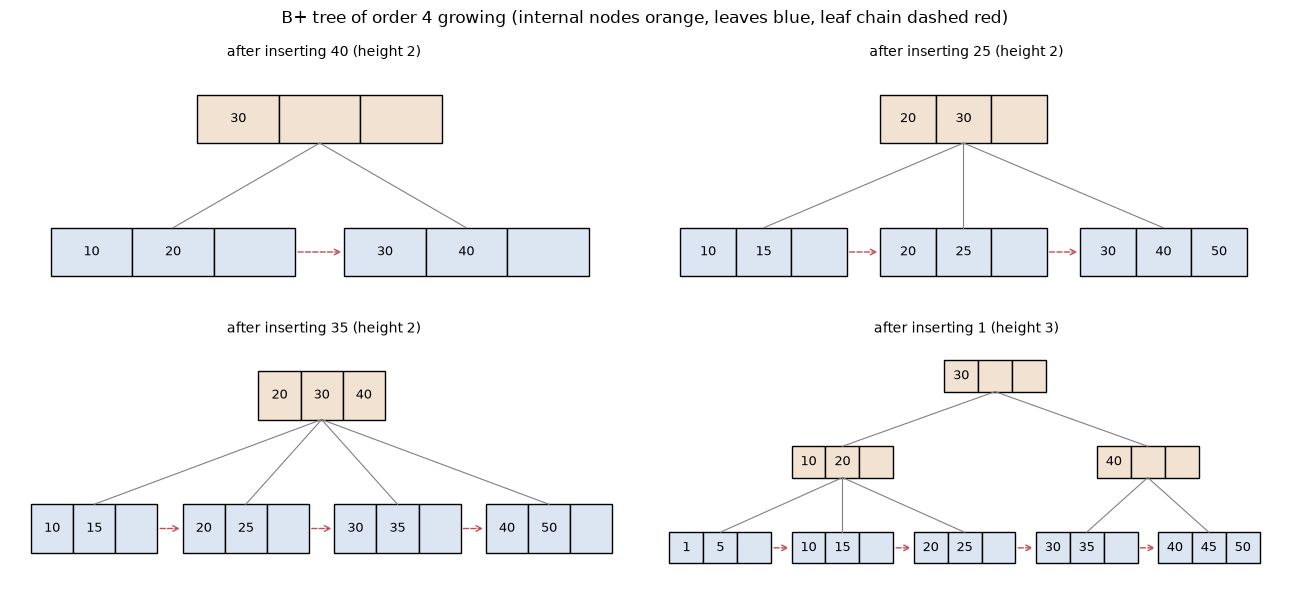

In [6]:
def draw_bplus(tree, ax, title, cell=1.0, gap=0.6, vgap=2.2):
    """Draw a B+ tree: each node is a row of n-1 key cells; dashed arrows show the leaf chain."""
    levels = tree.levels()
    width = tree.max_keys * cell
    pos = {}
    # leaves left to right
    for i, leaf in enumerate(levels[-1]):
        pos[id(leaf)] = (i * (width + gap), 0)
    # parents centred above their children
    for depth in range(len(levels) - 2, -1, -1):
        y = (len(levels) - 1 - depth) * vgap
        for nd in levels[depth]:
            xs = [pos[id(c)][0] for c in nd.children]
            pos[id(nd)] = ((xs[0] + xs[-1]) / 2, y)
    for depth, lvl in enumerate(levels):
        for nd in lvl:
            x, y = pos[id(nd)]
            for j in range(tree.max_keys):
                ax.add_patch(Rectangle((x + j * cell, y), cell, 0.8, fill=True,
                                       facecolor='#DCE6F2' if nd.leaf else '#F2E2D2', edgecolor='black'))
                if j < len(nd.keys):
                    ax.text(x + (j + 0.5) * cell, y + 0.4, str(nd.keys[j]), ha='center', va='center', fontsize=9)
            for c in nd.children:                                         # edges to children
                cx, cy = pos[id(c)]
                ax.plot([x + width / 2, cx + width / 2], [y, cy + 0.8], color='gray', lw=0.8)
    leaves = levels[-1]
    for a, b2 in zip(leaves, leaves[1:]):                                 # leaf chain
        (ax_, ay), (bx, by) = pos[id(a)], pos[id(b2)]
        ax.annotate('', xy=(bx, by + 0.4), xytext=(ax_ + width, ay + 0.4),
                    arrowprops=dict(arrowstyle='->', color='#C44E52', ls='--'))
    ax.set_xlim(-0.5, len(leaves) * (width + gap)); ax.set_ylim(-0.5, (len(levels) - 1) * vgap + 1.3)
    ax.set_title(title, fontsize=10); ax.axis('off')

fig, axes = plt.subplots(2, 2, figsize=(13, 6))
for ax, (k, snap) in zip(axes.ravel(), snapshots.items()):
    draw_bplus(snap, ax, f'after inserting {k} (height {snap.height()})')
plt.suptitle('B+ tree of order 4 growing (internal nodes orange, leaves blue, leaf chain dashed red)')
plt.tight_layout(); plt.show()

**What just happened?**
- Inserting **40** overflowed the leaf [10 20 30 40]; it split into [10 20] and [30 40] and **30 was copied up** into a new root.
- Inserting **25** and **35** split more leaves; their first keys (20, then 40) were copied into the root.
- Inserting **1** overflowed the leaf [1 5 10 15], whose split pushed a 5th child into the root [20 30 40]: the root split, **30 moved up**
  (it does not stay in the lower level) and the tree grew to **height 3**. All leaves are still at the same depth.

### Search and range queries
A search reads one node per level. A range query descends once to the leaf of `lo` and then follows the leaf links.

In [7]:
t.reads = 0
print('search(35) ->', t.search(35), '| nodes read:', t.reads)
t.reads = 0
print('search(36) ->', t.search(36), '| nodes read:', t.reads)
t.reads = 0
print('range(12, 47) ->', [k for k, _ in t.range(12, 47)], '| nodes read:', t.reads,
      '(3 to reach the first leaf + leaf hops)')

search(35) -> rid35 | nodes read: 3
search(36) -> None | nodes read: 3
range(12, 47) -> [15, 20, 25, 30, 35, 40, 45] | nodes read: 7 (3 to reach the first leaf + leaf hops)


### Deletion: borrow, merge, and the tree shrinking
We delete 45, 25, 5, 1, 10, 15 from the tree above and print what happens at each step.

In [8]:
for k in [45, 25, 5, 1, 10, 15]:
    t.events = []
    t.delete(k)
    check_invariants(t)                                  # every B+ tree rule still holds after each delete
    print(f'delete {k:>2}: {" | ".join(t.events) or "leaf still has enough keys"}')
    print('           ', str(t).replace(chr(10), '  //  '))

delete 45: leaf borrows 50 from right sibling, separator becomes 60
            [30]  //  [10 20]  [40 60]  //  [1 5]  [10 15]  [20 25]  [30 35]  [40 50]  [60 70]
delete 25: leaf merges with left sibling, parent loses a key
            [30]  //  [10]  [40 60]  //  [1 5]  [10 15 20]  [30 35]  [40 50]  [60 70]
delete  5: leaf borrows 10 from right sibling, separator becomes 15
            [30]  //  [15]  [40 60]  //  [1 10]  [15 20]  [30 35]  [40 50]  [60 70]
delete  1: leaf merges with right sibling, parent loses a key | internal node borrows through the parent from its right sibling
            [40]  //  [30]  [60]  //  [10 15 20]  [30 35]  [40 50]  [60 70]
delete 10: leaf still has enough keys
            [40]  //  [30]  [60]  //  [15 20]  [30 35]  [40 50]  [60 70]
delete 15: leaf merges with right sibling, parent loses a key | internal merge with right sibling, separator 40 comes down | root removed: tree shrinks to height 2
            [40 60]  //  [20 30 35]  [40 50]  [60 70]


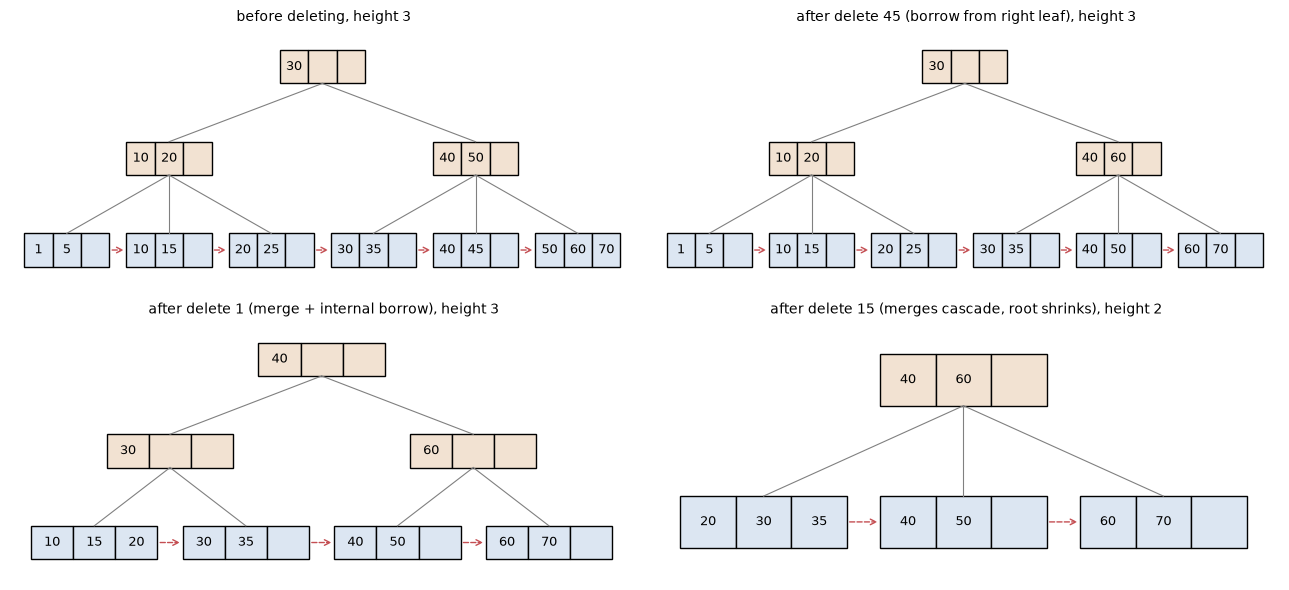

In [9]:
# Draw the deletion sequence, rebuilding the tree from scratch for each stage
stages = [('before deleting', []), ('after delete 45 (borrow from right leaf)', [45]),
          ('after delete 1 (merge + internal borrow)', [45, 25, 5, 1]),
          ('after delete 15 (merges cascade, root shrinks)', [45, 25, 5, 1, 10, 15])]
fig, axes = plt.subplots(2, 2, figsize=(13, 6))
for ax, (title, dels) in zip(axes.ravel(), stages):
    tr = build(order)
    for x in dels: tr.delete(x)
    draw_bplus(tr, ax, f'{title}, height {tr.height()}')
plt.tight_layout(); plt.show()

**What just happened?**
- **delete 45**: leaf [40 45] became [40] (below the minimum of 2). Its right sibling [50 60 70] had a spare key, so 50 was **borrowed**
  and the parent's separator changed to 60.
- **delete 25**: leaf [20] could not borrow (its left sibling [10 15] had only the minimum), so the two leaves **merged** into [10 15 20]
  and the parent lost the separator 20.
- **delete 5**: leaf [5] borrowed 10 from its right sibling [10 15 20].
- **delete 1**: the leaves merged, leaving their parent with one child; that internal node then **borrowed through the root** from its
  right sibling (a rotation: separator 30 came down, 40 went up).
- **delete 15**: a leaf merge left an internal node underfull with no spare sibling, so the two internal nodes **merged** (the root's
  separator 40 came down; delete 10 before it needed no fixing); the root was left with one child and was removed: **height 3 → 2**.

Stale separators (for example 30 above a leaf that no longer contains 30) are fine: separators only need to *separate*, not to exist as data.

### Does it really work? Random tests against a dict and a sorted list

In [10]:
t0 = time.perf_counter()
for n in [3, 4, 5, 8, 16, 64]:
    for seed in range(25):
        rng = random.Random(1000 * n + seed)
        tree, truth = BPlusTree(n), {}
        for step in range(1500):
            k = rng.randrange(800)
            if rng.random() < 0.65:
                tree.insert(k, k * 7); truth[k] = k * 7
            else:
                assert tree.delete(k) == (k in truth); truth.pop(k, None)
        assert check_invariants(tree) == len(truth)
        for k in range(800):
            assert tree.search(k) == truth.get(k)                             # point lookups == dict
        srt = sorted(truth)
        for _ in range(30):
            lo = rng.randrange(800); hi = lo + rng.randrange(200)
            expect = [(k, truth[k]) for k in srt[bisect.bisect_left(srt, lo):bisect.bisect_right(srt, hi)]]
            assert tree.range(lo, hi) == expect                               # range queries == sorted list
print(f'150 random trees (orders 3..64, 1,500 mixed inserts/deletes each) agree with dict + sorted list '
      f'({time.perf_counter() - t0:.1f} s)')

150 random trees (orders 3..64, 1,500 mixed inserts/deletes each) agree with dict + sorted list (6.6 s)


**Complexity** (N keys, order n, height h = O(log_{n/2} N)):

| Operation | Node (block) reads | CPU |
|---|---|---|
| search | h | O(h log n) (binary search inside each node) |
| range query returning k keys | h + ⌈k / leaf size⌉ | O(h log n + k) |
| insert / delete | h reads + O(h) writes in the worst case (splits/merges up to the root) | O(h · n) |
| space | O(N), nodes at least about half full | |

> ⚠️ **Common mistake.** In a leaf split the separator is **copied** up (it must stay in the leaf, because only leaves hold data);
> in an internal split it is **moved** up. Mixing these up is the most common exam error.

> 🎓 **Exam tip.** Textbooks differ on "order": Silberschatz's n = max pointers per node; Knuth's order = max children;
> some courses (Ramakrishnan) use d = minimum occupancy, so a node holds d to 2d keys. Always state which definition you use.

---
## 4. Order, fan-out and height: the exam formulas

> **In plain English:** how many keys fit in one page decides how many levels the tree needs; with thousands per page, 3 or 4 levels cover billions of rows.

**Order from the block size.** An internal node with n pointers (P bytes each) and n − 1 keys (K bytes each) must fit in a block of B bytes:

  n·P + (n − 1)·K ≤ B  ⇒  **n = ⌊(B + K) / (P + K)⌋**

A leaf holds m (key, record-pointer) pairs plus one next-leaf pointer: m·(K + P_r) + P ≤ B ⇒ **m = ⌊(B − P) / (K + P_r)⌋**.

**Height for N keys.** Each level multiplies the number of reachable keys by the fan-out, so the height is logarithmic:
- best case (every node full): h_min = 1 + ⌈log_n ⌈N / (n−1)⌉⌉
- worst case (every node as empty as allowed): leaves ≥ 2·⌈n/2⌉^(h−2) and each holds ≥ ⌈(n−1)/2⌉ keys, so h_max is the largest h with
  2·⌈n/2⌉^(h−2)·⌈(n−1)/2⌉ ≤ N. Silberschatz's rule of thumb: the path is no longer than ⌈log_{⌈n/2⌉}(N)⌉.

**Elmasri's example:** B = 512 bytes, key V = 9 bytes, block pointer P = 6 bytes, record pointer Pr = 7 bytes.

In [11]:
def internal_order(B, K, P):
    return (B + K) // (P + K)                # n*P + (n-1)*K <= B

def leaf_capacity(B, K, Pr, P):
    return (B - P) // (K + Pr)               # m*(K+Pr) + P <= B

def height_bounds(N, n):
    """(min, max) number of levels of an order-n B+ tree holding N >= 1 keys."""
    h, nodes = 1, math.ceil(N / (n - 1))
    while nodes > 1:
        nodes, h = math.ceil(nodes / n), h + 1
    d, min_leaf = math.ceil(n / 2), math.ceil((n - 1) / 2)
    if N < 2 * min_leaf:
        return h, 1
    hmax = 2
    while 2 * min_leaf * d ** (hmax - 1) <= N:  # can a tree one level taller still hold only N keys?
        hmax += 1
    return h, hmax

print('Elmasri: internal order p =', internal_order(512, 9, 6), '| leaf capacity p_leaf =', leaf_capacity(512, 9, 7, 6))
n4k = internal_order(4096, 8, 8)
print('4 KB page, 8-byte keys and pointers: n =', n4k, '| leaf capacity =', leaf_capacity(4096, 8, 8, 8))

rows = []
for N in [10**3, 10**6, 10**9, 10**12]:
    lo, hi = height_bounds(N, n4k)
    rows.append(dict(N=f'{N:.0e}', min_levels=lo, max_levels=hi,
                     silberschatz_bound=math.ceil(math.log(N, math.ceil(n4k / 2)))))
print(pd.DataFrame(rows).to_string(index=False))

Elmasri: internal order p = 34 | leaf capacity p_leaf = 31
4 KB page, 8-byte keys and pointers: n = 256 | leaf capacity = 255
    N  min_levels  max_levels  silberschatz_bound
1e+03           2           2                   2
1e+06           3           3                   3
1e+09           4           5                   5
1e+12           5           6                   6


**What just happened?** Elmasri's numbers come out as in the book: **p = 34** pointers per internal node and **31** entries per leaf.
With 4 KB pages and 8-byte keys the order is **256**, and even a **trillion** keys need at most 6 levels. In practice the root and the
second level are always cached in the buffer pool, so a lookup in a billion-row table costs 1 to 2 real I/Os.

Let us check the height bounds empirically with our own tree.

In [12]:
rows = []
for n in [4, 8, 16, 32]:
    for N in [1_000, 20_000]:
        tr = BPlusTree(n)
        for k in random.Random(n * N).sample(range(10 * N), N):
            tr.insert(k, None)
        lo, hi = height_bounds(N, n)
        leaves = tr.levels()[-1]
        fill = np.mean([len(l.keys) for l in leaves]) / (n - 1)
        assert lo <= tr.height() <= hi                     # the measured height respects both bounds
        rows.append(dict(order_n=n, N=N, measured_height=tr.height(), min_possible=lo, max_possible=hi,
                         avg_leaf_fill=round(fill, 2)))
print(pd.DataFrame(rows).to_string(index=False))

 order_n     N  measured_height  min_possible  max_possible  avg_leaf_fill
       4  1000                7             6             9           0.78
       4 20000                9             8            14           0.78
       8  1000                4             4             5           0.72
       8 20000                6             5             7           0.73
      16  1000                3             3             3           0.70
      16 20000                4             4             5           0.72
      32  1000                3             3             3           0.67
      32 20000                4             3             4           0.69


**What just happened?** Every measured height lies between the best-case and worst-case bounds, close to the best case.
With random insertion order the leaves end up about **70% full** (theory for large nodes and random inserts: ln 2 ≈ 0.69),
which is why textbooks estimate the typical fan-out as about ⅔ of the maximum.

> ⚠️ **Common mistake.** Bulk-loading a B+ tree by inserting **sorted** keys one at a time leaves every leaf half full (each split leaves a half-empty
> left node behind). Databases bulk-load bottom-up instead: sort the keys, fill leaves to a chosen fill factor, then build the levels above.

---
## 5. Hash-based indexing

> **In plain English:** a hash index turns a key into a bucket number, like a cloakroom ticket, so exact lookups take one step (but ranges are impossible).

**Analogy.** A cloakroom: the attendant gives you ticket number 37, and your coat is on hook 37. No searching at all.
A **hash index** computes a **bucket** number h(key) and stores the entry in that bucket (one or a few blocks).
Equality lookups cost about **1 block read**, but hashing destroys order, so **range queries cannot use it**.

### 5.1 Static hashing with overflow chains
A fixed number M of buckets. When a bucket's block is full, an **overflow block** is chained to it. As the file grows, chains get long
and lookups slow down: the classic weakness of static hashing.

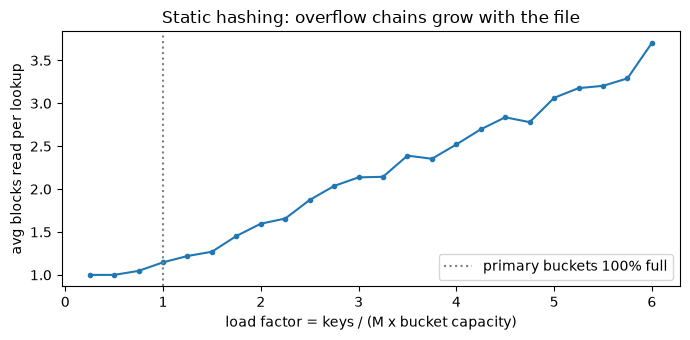

at load 6.0: 3.70 blocks per successful lookup


In [13]:
class StaticHash:
    """M primary buckets, each a chain of blocks holding up to `cap` keys."""
    def __init__(self, M, cap):
        self.M, self.cap = M, cap
        self.buckets = [[[]] for _ in range(M)]            # bucket -> list of blocks -> list of keys
    def h(self, key):
        return (key * 2654435761) % 2**32 % self.M          # Knuth's multiplicative hash, then mod M
    def insert(self, key):
        chain = self.buckets[self.h(key)]
        if len(chain[-1]) == self.cap:
            chain.append([])                                 # allocate an overflow block
        chain[-1].append(key)
    def lookup_cost(self, key):
        """Blocks read to find key (walk the chain until found)."""
        for i, blk in enumerate(self.buckets[self.h(key)]):
            if key in blk:
                return i + 1
        return len(self.buckets[self.h(key)])

M, CAP = 100, 10
sh, inserted, curve = StaticHash(M, CAP), [], []
stream = random.Random(5).sample(range(10**7), 6000)
for i, k in enumerate(stream, 1):
    sh.insert(k); inserted.append(k)
    if i % 250 == 0:
        sample = random.Random(i).sample(inserted, min(300, len(inserted)))
        curve.append((i / (M * CAP), np.mean([sh.lookup_cost(x) for x in sample])))
x, y = zip(*curve)
plt.figure(figsize=(7, 3.5))
plt.plot(x, y, marker='o', ms=3)
plt.axvline(1.0, color='gray', ls=':', label='primary buckets 100% full')
plt.xlabel('load factor = keys / (M x bucket capacity)'); plt.ylabel('avg blocks read per lookup')
plt.title('Static hashing: overflow chains grow with the file'); plt.legend(); plt.tight_layout(); plt.show()
print(f'at load {x[-1]:.1f}: {y[-1]:.2f} blocks per successful lookup')

**What just happened?** Up to a load factor of about 0.8 nearly every lookup costs 1 block. Beyond that, overflow chains
form; at 6x the planned size a lookup reads several blocks and keeps getting worse. Re-hashing everything into a bigger table would
fix it, but blocks the database while it runs. **Dynamic hashing** grows gradually instead.

### 5.2 Extendible hashing
- A **directory** of 2^g pointers to buckets, where **g = global depth**. A key goes to directory entry = the last g bits of h(key).
- Each bucket has a **local depth l ≤ g**: all its keys agree on their last l bits, and 2^(g−l) directory entries point to it.
- **Insert into a full bucket** with local depth l:
  - if l < g: **split the bucket** only (l += 1, redistribute its keys on bit l, repoint half of its directory entries);
  - if l = g: first **double the directory** (g += 1, each new entry copies its "twin"), then split.
- The directory is small (a few pointers), so it usually lives in memory: **one block read per lookup**, and no overflow chains as long as
  the keys' hash bits differ.

We use h(k) = k for the hand trace so you can read the bits directly, and bucket capacity 2.

In [14]:
class Bucket:
    def __init__(self, depth, bid):
        self.depth, self.items, self.id = depth, {}, bid

class ExtendibleHash:
    def __init__(self, capacity=2, h=lambda k: k):
        self.cap, self.h = capacity, h
        self.global_depth = 0
        self.n_buckets = 1
        self.dir = [Bucket(0, 'B0')]                         # 2**0 = 1 directory entry
        self.log = []

    def _index(self, key):
        return self.h(key) & ((1 << self.global_depth) - 1)  # last global_depth bits

    def get(self, key):
        return self.dir[self._index(key)].items.get(key)

    def put(self, key, value=None):
        b = self.dir[self._index(key)]
        if key in b.items or len(b.items) < self.cap:
            b.items[key] = value
            return
        if b.depth == self.global_depth:                     # no spare bit: double the directory
            self.dir = self.dir + self.dir                   # entry i and i + 2**g point to the same bucket
            self.global_depth += 1
            self.log.append(f'insert {key}: directory doubles to {len(self.dir)} entries (global depth {self.global_depth})')
        b.depth += 1                                         # split b on its new bit
        new = Bucket(b.depth, f'B{self.n_buckets}'); self.n_buckets += 1
        bit = 1 << (b.depth - 1)
        old_items, b.items = b.items, {}
        for k, v in old_items.items():
            (new if self.h(k) & bit else b).items[k] = v
        for i in range(len(self.dir)):                       # repoint the entries whose new bit is 1
            if self.dir[i] is b and i & bit:
                self.dir[i] = new
        self.log.append(f'insert {key}: split {b.id} -> {b.id}/{new.id} (local depth {b.depth})')
        self.put(key, value)                                 # retry: may split again if all keys went one way

    def table(self):
        g = self.global_depth
        return pd.DataFrame([dict(entry=format(i, f'0{g}b') if g else '-', bucket=b.id, local_depth=b.depth,
                                  keys=sorted(b.items), key_bits=[format(k, '05b') for k in sorted(b.items)])
                             for i, b in enumerate(self.dir)])

def check_extendible(eh):
    g = eh.global_depth
    assert len(eh.dir) == 2 ** g
    refs_of = defaultdict(list)                              # bucket -> directory entries pointing to it
    for i, x in enumerate(eh.dir):
        refs_of[id(x)].append(i)
    buckets = {id(b): b for b in eh.dir}.values()
    for b in buckets:
        refs = refs_of[id(b)]
        assert len(refs) == 2 ** (g - b.depth)               # 2^(g-l) entries point to a bucket of depth l
        mask = (1 << b.depth) - 1
        assert all((eh.h(k) & mask) == (refs[0] & mask) for k in b.items)   # keys agree on the last l bits
    return len(buckets)

eh = ExtendibleHash(capacity=2)
for k in [16, 4, 6, 22, 24, 10, 31, 7, 9, 20, 26]:
    eh.put(k)
    check_extendible(eh)
print('\n'.join(eh.log))
print(f'\nglobal depth = {eh.global_depth}')
print(eh.table().to_string(index=False))

insert 6: directory doubles to 2 entries (global depth 1)
insert 6: split B0 -> B0/B1 (local depth 1)
insert 6: directory doubles to 4 entries (global depth 2)
insert 6: split B0 -> B0/B2 (local depth 2)
insert 24: directory doubles to 8 entries (global depth 3)
insert 24: split B0 -> B0/B3 (local depth 3)
insert 10: split B2 -> B2/B4 (local depth 3)
insert 9: split B1 -> B1/B5 (local depth 2)

global depth = 3
entry bucket  local_depth     keys       key_bits
  000     B0            3 [16, 24] [10000, 11000]
  001     B1            2      [9]        [01001]
  010     B2            3 [10, 26] [01010, 11010]
  011     B5            2  [7, 31] [00111, 11111]
  100     B3            3  [4, 20] [00100, 10100]
  101     B1            2      [9]        [01001]
  110     B4            3  [6, 22] [00110, 10110]
  111     B5            2  [7, 31] [00111, 11111]


**What just happened?** Read the log from the top:
- 16 (10000) and 4 (00100) filled the single bucket; inserting 6 (00110) forced the directory to double, then split on the last bit.
  All three keys are even (last bit 0), so they all landed in the same bucket and the insert **retried**, doubling again: splits
  continue until the keys' bits differ.
- Later splits of buckets whose local depth was already below the global depth (when 10 and 9 arrived) did **not** double the directory.
- In the final table several directory entries point to the **same** bucket: exactly 2^(g−l) of them, as the invariant check asserts.

Now a stress test with a scrambling hash, 20,000 keys and 8 keys per bucket.

In [15]:
mix = lambda k: (k * 2654435761) & 0xFFFFFFFF           # spread the bits of integer keys
eh2, truth = ExtendibleHash(capacity=8, h=mix), {}
for k in random.Random(1).sample(range(10**8), 20_000):
    eh2.put(k, str(k)); truth[k] = str(k)
nb = check_extendible(eh2)
assert all(eh2.get(k) == v for k, v in truth.items())
assert all(eh2.get(k) is None for k in random.Random(2).sample(range(10**8, 2 * 10**8), 1000))
util = len(truth) / (nb * 8)
print(f'20,000 keys: global depth {eh2.global_depth}, directory {len(eh2.dir)} entries, {nb} buckets, '
      f'space utilization {util:.2f}')

20,000 keys: global depth 14, directory 16384 entries, 3620 buckets, space utilization 0.69


**What just happened?** Every key is found, every absent key is reported missing, and the invariants hold. The buckets are about
**69% full on average**, the theoretical ln 2 for extendible hashing with random keys. The directory has more entries than there are buckets
because of the skew in which buckets happened to split. If many keys share all their hash bits (heavy duplicates), extendible hashing
keeps doubling uselessly, so real implementations fall back to overflow pages.

### 5.3 Linear hashing (briefly)
**Linear hashing** (Litwin, 1980) needs **no directory**. Buckets are split **in a fixed round-robin order** (pointer `next`), one at a time,
whenever the load factor passes a threshold, regardless of which bucket overflowed (it uses overflow chains meanwhile).
With N₀ initial buckets and current `level`, a key goes to h(k) mod (N₀·2^level); if that bucket was already split this round (index < next),
use h(k) mod (N₀·2^(level+1)) instead.

In [16]:
class LinearHash:
    def __init__(self, n0=2, cap=4, max_load=0.8):
        self.n0, self.cap, self.max_load = n0, cap, max_load
        self.level, self.next, self.count = 0, 0, 0
        self.buckets = [[] for _ in range(n0)]               # each bucket: list of keys (beyond cap = overflow)
    def _addr(self, key):
        h = mix(key)
        a = h % (self.n0 * 2 ** self.level)
        if a < self.next:                                     # this bucket was already split this round
            a = h % (self.n0 * 2 ** (self.level + 1))
        return a
    def insert(self, key):
        self.buckets[self._addr(key)].append(key); self.count += 1
        if self.count / (len(self.buckets) * self.cap) > self.max_load:
            self._split()
    def _split(self):
        old, self.buckets[self.next] = self.buckets[self.next], []
        self.buckets.append([])                               # the new bucket is next + n0 * 2**level
        mod = self.n0 * 2 ** (self.level + 1)
        for k in old:
            self.buckets[mix(k) % mod].append(k)
        self.next += 1
        if self.next == self.n0 * 2 ** self.level:            # round finished: start the next level
            self.level, self.next = self.level + 1, 0
    def contains(self, key):
        return key in self.buckets[self._addr(key)]

lh = LinearHash()
data = random.Random(3).sample(range(10**8), 20_000)
for k in data:
    lh.insert(k)
assert all(lh.contains(k) for k in data) and not any(lh.contains(k) for k in range(10**8, 10**8 + 500))
over = sum(max(0, math.ceil(len(b) / lh.cap) - 1) for b in lh.buckets)
print(f'{len(lh.buckets)} buckets, level {lh.level}, next {lh.next}, overflow blocks {over} '
      f'({over / len(lh.buckets):.2f} per bucket)')

6250 buckets, level 11, next 2154, overflow blocks 1618 (0.26 per bucket)


**What just happened?** The file grew from 2 to thousands of buckets one split at a time, with no directory. The price is overflow
blocks (about one per four buckets here): the bucket that splits is the next one in round-robin order, not necessarily the one that overflowed. Linear hashing is used in Berkeley DB and was the basis of PostgreSQL's hash index design.

| Scheme | Directory | Growth | Worst case |
|---|---|---|---|
| Static | none | none (rehash everything) | long overflow chains |
| Extendible | yes, doubles | split the full bucket | directory doubling; bad with many equal hashes |
| Linear | none | split buckets round-robin | temporary overflow chains |

> 🎓 **Exam tip.** "Why not use a hash index for `WHERE salary BETWEEN 50k AND 60k`?" Because hashing scatters adjacent keys across
> buckets; only a tree (or sorted) index supports range queries and `ORDER BY`.

---
## 6. Bitmap indexes

> **In plain English:** for a column with few possible values, keep one row of yes/no bits per value and answer questions by combining bit rows.

For a column with few distinct values (a **low-cardinality** column: gender, country, status), keep one **bit vector per value**:
bit i is 1 if row i has that value. Queries become bitwise operations on whole machine words, which are very fast.

```
row:            0 1 2 3 4 5 6 7
region = EU  :  1 0 0 1 0 1 0 0
region = US  :  0 1 1 0 0 0 1 0
plan   = pro :  1 1 0 0 0 1 1 0
EU AND pro   :  1 0 0 0 0 1 0 0   -> rows 0 and 5
```

In [17]:
class BitmapIndex:
    """One Python int per distinct value, used as a bit vector (bit i = row i)."""
    def __init__(self, column):
        col = np.asarray(column)
        self.n = len(col)
        self.bitmaps = {}
        for v in pd.unique(col):
            mask = np.packbits(col == v, bitorder='little')  # bit i of the bitmap = (row i has value v)
            self.bitmaps[v] = int.from_bytes(mask.tobytes(), 'little')
    def eq(self, v):
        return self.bitmaps.get(v, 0)
    def any_of(self, values):                                # OR of several bitmaps (IN list)
        out = 0
        for v in values:
            out |= self.eq(v)
        return out
    def all_rows(self):
        return (1 << self.n) - 1

def rows_of(bits, n=None):
    """Row numbers whose bit is 1 (unpacked with numpy, so it is fast even for 200,000 bits)."""
    n = n or bits.bit_length()
    raw = np.frombuffer(bits.to_bytes((n + 7) // 8, 'little'), dtype=np.uint8)
    return np.flatnonzero(np.unpackbits(raw, bitorder='little')[:n]).tolist()

small = pd.DataFrame({'region': ['EU', 'US', 'US', 'EU', 'APAC', 'EU', 'US', 'APAC'],
                      'plan':   ['pro', 'pro', 'free', 'free', 'free', 'pro', 'pro', 'team']})
bi_r, bi_p = BitmapIndex(small.region), BitmapIndex(small.plan)
show = pd.DataFrame({f'region={v}': [b >> i & 1 for i in range(8)] for v, b in sorted(bi_r.bitmaps.items())})
for v, b in sorted(bi_p.bitmaps.items()):
    show[f'plan={v}'] = [b >> i & 1 for i in range(8)]
print(show.T.to_string())
print('EU AND pro ->', rows_of(bi_r.eq('EU') & bi_p.eq('pro')))

             0  1  2  3  4  5  6  7
region=APAC  0  0  0  0  1  0  0  1
region=EU    1  0  0  1  0  1  0  0
region=US    0  1  1  0  0  0  1  0
plan=free    0  0  1  1  1  0  0  0
plan=pro     1  1  0  0  0  1  1  0
plan=team    0  0  0  0  0  0  0  1
EU AND pro -> [0, 5]


In [18]:
# A 200,000-row table; compare bitmap answers with pandas
rng = np.random.default_rng(0)
n_rows = 200_000
df = pd.DataFrame({'region':  rng.choice(['EU', 'US', 'APAC', 'LATAM'], n_rows, p=[0.35, 0.35, 0.2, 0.1]),
                   'plan':    rng.choice(['free', 'pro', 'team'], n_rows, p=[0.7, 0.2, 0.1]),
                   'churned': rng.random(n_rows) < 0.1})
t0 = time.perf_counter()
bx = {c: BitmapIndex(df[c].tolist()) for c in df.columns}
build_s = time.perf_counter() - t0

queries = {
    "region='EU' AND plan='pro' AND NOT churned":
        (lambda: bx['region'].eq('EU') & bx['plan'].eq('pro') & ~bx['churned'].eq(True) & bx['region'].all_rows(),
         lambda: (df.region == 'EU') & (df.plan == 'pro') & ~df.churned),
    "region IN ('US','LATAM') OR plan='team'":
        (lambda: bx['region'].any_of(['US', 'LATAM']) | bx['plan'].eq('team'),
         lambda: df.region.isin(['US', 'LATAM']) | (df.plan == 'team')),
    "churned AND plan <> 'free'":
        (lambda: bx['churned'].eq(True) & (bx['plan'].all_rows() & ~bx['plan'].eq('free')),
         lambda: df.churned & (df.plan != 'free')),
}
rows = []
for q, (bitmap_fn, pandas_fn) in queries.items():
    t0 = time.perf_counter(); bits = bitmap_fn(); t_bm = time.perf_counter() - t0
    count = bits.bit_count()                                  # popcount = number of matching rows
    expect = int(pandas_fn().sum())
    assert count == expect
    assert rows_of(bits, n_rows) == np.flatnonzero(pandas_fn().to_numpy()).tolist()   # the exact same rows
    rows.append(dict(query=q, matching_rows=count, bitmap_ms=round(1000 * t_bm, 3)))
print(f'built 9 bitmaps over {n_rows:,} rows in {build_s:.2f} s; each bitmap = {n_rows // 8:,} bytes uncompressed')
print(pd.DataFrame(rows).to_string(index=False))

built 9 bitmaps over 200,000 rows in 0.40 s; each bitmap = 25,000 bytes uncompressed
                                     query  matching_rows  bitmap_ms
region='EU' AND plan='pro' AND NOT churned          12592      0.113
   region IN ('US','LATAM') OR plan='team'         101105      0.036
                churned AND plan <> 'free'           6045      0.159


**What just happened?** Each query was answered with a few bitwise operations on 25 KB bit vectors, and `bit_count()` (popcount)
gave the number of matching rows; both counts and row ids match pandas exactly. Note `NOT` needs care: `~x` must be masked with
"all rows" (and real systems also exclude deleted rows and NULLs, using an existence bitmap).

| | Bitmap index | B+ tree index |
|---|---|---|
| Best for | low-cardinality columns, ad-hoc AND/OR of many predicates, `COUNT(*)` | high-cardinality keys, point and range lookups |
| Size | rows × distinct values bits (compressible: run-length, WAH, **Roaring** bitmaps) | about one entry per row |
| Updates | expensive (many bitmaps, compressed runs to rewrite; locking a bitmap locks many rows) | cheap, local |
| Where | data warehouses / OLAP (Oracle bitmap indexes, Druid, Pinot, ClickHouse skip indexes, Lucene filters) | OLTP everywhere |

---
## 7. Inverted indexes and BM25

> **In plain English:** a search engine keeps, for every word, the list of documents containing it, then ranks those documents by how well they match.

A **forward index** maps document → words. An **inverted index** maps **term → postings list**: the sorted list of documents (and positions)
that contain the term. This is the core data structure of every search engine (Lucene, Elasticsearch, OpenSearch, Solr, Tantivy) and of
the keyword half of hybrid retrieval in RAG systems.

- **AND query**: intersect the postings lists with a two-pointer merge, O(|p₁| + |p₂|) (start with the shortest list).
- **OR query**: merge (union) the lists.
- **Phrase query** ("vector database"): AND, then check that the positions are consecutive.
- **Ranking**: **BM25** (Robertson & Spärck Jones et al.) scores a document D for query Q as

  score(D, Q) = Σ_{t ∈ Q} IDF(t) · f(t, D)·(k₁ + 1) / ( f(t, D) + k₁·(1 − b + b·|D| / avgdl) )

  where f(t, D) is the term frequency, |D| the document length, avgdl the average length, k₁ ≈ 1.2–2.0 (term-frequency saturation),
  b = 0.75 (length normalization), and IDF(t) = ln( (N − n_t + 0.5)/(n_t + 0.5) + 1 ) (the Lucene form, never negative).

In [19]:
docs = [
    'A B+ tree index keeps keys sorted so range queries are fast.',
    'Hash indexes give fast equality lookups but cannot answer range queries.',
    'A vector database stores embeddings and answers nearest neighbour queries.',
    'Bitmap indexes work well for low cardinality columns in a data warehouse.',
    'The query optimizer decides whether to use an index or a full table scan.',
    'An inverted index maps each term to the documents containing it, as in a search engine.',
    'Hybrid search combines BM25 keyword scores with vector database similarity.',
    'Write-ahead logging makes the database recover after a crash.',
]
STOP = {'a', 'an', 'the', 'and', 'but', 'or', 'to', 'of', 'in', 'it', 'as', 'so', 'for', 'each', 'with', 'after', 'are', 'is'}

def tokenize(text):
    return [w for w in re.findall(r'[a-z0-9+]+', text.lower()) if w not in STOP]

class InvertedIndex:
    def __init__(self, docs):
        self.postings = defaultdict(list)        # term -> [(doc_id, [positions])] sorted by doc_id
        self.doc_len = []
        for d, text in enumerate(docs):
            toks = tokenize(text)
            self.doc_len.append(len(toks))
            positions = defaultdict(list)
            for p, tok in enumerate(toks):
                positions[tok].append(p)
            for tok, ps in positions.items():
                self.postings[tok].append((d, ps))   # doc ids arrive in increasing order: lists stay sorted
        self.N, self.avgdl = len(docs), sum(self.doc_len) / len(docs)

    def docs_with(self, term):
        return [d for d, _ in self.postings.get(term, [])]

    @staticmethod
    def intersect(p1, p2):
        """Two-pointer merge of two sorted doc-id lists."""
        i = j = 0; out = []
        while i < len(p1) and j < len(p2):
            if p1[i] == p2[j]: out.append(p1[i]); i += 1; j += 1
            elif p1[i] < p2[j]: i += 1
            else: j += 1
        return out

    def AND(self, *terms):
        lists = sorted((self.docs_with(t) for t in terms), key=len)   # shortest list first
        out = lists[0]
        for l in lists[1:]:
            out = self.intersect(out, l)
        return out

    def OR(self, *terms):
        return sorted(set().union(*(self.docs_with(t) for t in terms)))

    def phrase(self, text):
        terms = tokenize(text)
        hits = []
        for d in self.AND(*terms):
            pos = [dict(self.postings[t])[d] for t in terms]
            if any(all(p + k in pos[k] for k in range(1, len(terms))) for p in pos[0]):
                hits.append(d)
        return hits

    def bm25(self, query, k1=1.2, b=0.75):
        scores = defaultdict(float)
        for t in tokenize(query):
            plist = self.postings.get(t, [])
            idf = math.log((self.N - len(plist) + 0.5) / (len(plist) + 0.5) + 1)
            for d, ps in plist:
                tf = len(ps)
                scores[d] += idf * tf * (k1 + 1) / (tf + k1 * (1 - b + b * self.doc_len[d] / self.avgdl))
        return sorted(scores.items(), key=lambda kv: -kv[1])

ix = InvertedIndex(docs)
print('postings for "index"   :', ix.postings['index'])
print('postings for "queries" :', ix.postings['queries'])
brute_and = lambda *ts: [d for d, text in enumerate(docs) if all(t in tokenize(text) for t in ts)]
for terms in [('index', 'queries'), ('vector', 'database'), ('range', 'queries'), ('database',)]:
    assert ix.AND(*terms) == brute_and(*terms)           # same answer as scanning every document
    print(f'AND{terms}:', ix.AND(*terms))
print('OR(bitmap, hash)          :', ix.OR('bitmap', 'hash'))
print('phrase "vector database"  :', ix.phrase('vector database'))
print('phrase "database vector"  :', ix.phrase('database vector'))
print('\nBM25 ranking for "vector database index":')
for d, s in ix.bm25('vector database index')[:4]:
    print(f'  {s:.3f}  doc {d}: {docs[d]}')

postings for "index"   : [(0, [2]), (4, [5]), (5, [1])]
postings for "queries" : [(0, [7]), (1, [9]), (2, [7])]
AND('index', 'queries'): [0]
AND('vector', 'database'): [2, 6]
AND('range', 'queries'): [0, 1]
AND('database',): [2, 6, 7]
OR(bitmap, hash)          : [1, 3]
phrase "vector database"  : [2, 6]
phrase "database vector"  : []

BM25 ranking for "vector database index":
  2.293  doc 2: A vector database stores embeddings and answers nearest neighbour queries.
  2.187  doc 6: Hybrid search combines BM25 keyword scores with vector database similarity.
  1.023  doc 7: Write-ahead logging makes the database recover after a crash.
  0.973  doc 5: An inverted index maps each term to the documents containing it, as in a search engine.


In [20]:
# Optional cross-check with SQLite's built-in full-text engine (FTS5), if this SQLite build has it
try:
    con = sqlite3.connect(':memory:')
    con.execute('CREATE VIRTUAL TABLE d USING fts5(body)')
    con.executemany('INSERT INTO d(rowid, body) VALUES (?, ?)', list(enumerate(docs)))
    for terms in [('index', 'queries'), ('vector', 'database')]:
        got = [r[0] for r in con.execute('SELECT rowid FROM d WHERE d MATCH ? ORDER BY rowid', (' AND '.join(terms),))]
        assert got == ix.AND(*terms)
        print(f'FTS5 MATCH {" AND ".join(terms)!r:28} -> {got} (same as ours)')
    con.close()
except sqlite3.OperationalError as e:
    print('FTS5 not available in this SQLite build:', e)

FTS5 MATCH 'index AND queries'          -> [0] (same as ours)
FTS5 MATCH 'vector AND database'        -> [2, 6] (same as ours)


**What just happened?** Our inverted index answered AND, OR and phrase queries exactly like a brute-force scan (and like SQLite's FTS5).
The phrase query used **positions**: "vector database" matches docs 2 and 6, while "database vector" matches nothing.
BM25 ranked doc 2 first: it contains both "vector" and "database" in a short document; doc 6 contains both too but is longer, so length
normalization (b) lowers its score. Documents matching only "index" or only "database" score lower: one fairly common term each.

Complexity: building is O(total tokens); an AND of two terms is O(|p₁| + |p₂|); real engines add **skip pointers** and compress
postings (delta + variable-byte encoding) so that lists of millions of doc ids are scanned in milliseconds.

---
## 8. Indexes in SQLite: EXPLAIN QUERY PLAN, covering and clustered indexes

> **In plain English:** we create real indexes in SQLite, ask it how it plans to run each query, and time the difference.

SQLite stores **every table as a B-tree** keyed by the `rowid` (an `INTEGER PRIMARY KEY` *is* the rowid), so an ordinary table is
**clustered on its rowid**. Every `CREATE INDEX` builds a separate B-tree of (indexed columns, rowid): a **secondary, non-clustered** index.
A `WITHOUT ROWID` table is clustered on its declared `PRIMARY KEY` instead.

`EXPLAIN QUERY PLAN` shows what the optimizer chose: `SCAN` = full table (or full index) scan, `SEARCH ... USING INDEX` = B-tree descent,
`USING COVERING INDEX` = the index alone answers the query, `USE TEMP B-TREE FOR ORDER BY` = an explicit sort.

We build a 200,000-row `orders` table.

In [21]:
con = sqlite3.connect(':memory:')
rng = np.random.default_rng(42)
N_ORD = 200_000
orders = pd.DataFrame({
    'customer_id': rng.integers(1, 20_001, N_ORD),
    'amount':      np.round(rng.gamma(2.0, 40.0, N_ORD), 2),
    'quantity':    rng.integers(1, 10, N_ORD),
    'status':      rng.choice(['paid', 'refunded', 'pending'], N_ORD, p=[0.9, 0.04, 0.06]),
    'created':     (pd.Timestamp('2024-01-01') + pd.to_timedelta(rng.integers(0, 730 * 86400, N_ORD), unit='s')).astype(str),
})
con.execute('CREATE TABLE orders(id INTEGER PRIMARY KEY, customer_id INT, amount REAL, quantity INT, status TEXT, created TEXT)')
con.executemany('INSERT INTO orders(customer_id, amount, quantity, status, created) VALUES (?,?,?,?,?)',
                zip(*(orders[c].tolist() for c in orders.columns)))     # .tolist() gives plain Python values
con.commit()

def plan(sql, params=()):
    """The optimizer's plan, one string per step."""
    return [row[3] for row in con.execute('EXPLAIN QUERY PLAN ' + sql, params)]

def bench(sql, param_list, repeat=3):
    """Milliseconds per query: run sql once per params tuple, best of `repeat` passes."""
    best = math.inf
    for _ in range(repeat):
        t0 = time.perf_counter()
        for p in param_list:
            con.execute(sql, p).fetchall()
        best = min(best, time.perf_counter() - t0)
    return 1000 * best / len(param_list)

lookups = [(int(c),) for c in rng.integers(1, 20_001, 50)]
q_cust = 'SELECT id, amount FROM orders WHERE customer_id = ?'
print('rows:', con.execute('SELECT COUNT(*) FROM orders').fetchone()[0])
print('BEFORE index :', plan(q_cust, lookups[0]))
before_ms = bench(q_cust, lookups)
truth = {p: sorted(con.execute(q_cust, p).fetchall()) for p in lookups[:10]}

con.execute('CREATE INDEX idx_cust ON orders(customer_id)')
print('AFTER index  :', plan(q_cust, lookups[0]))
after_ms = bench(q_cust, lookups)
assert all(sorted(con.execute(q_cust, p).fetchall()) == truth[p] for p in truth)   # same answers
print(f'lookup by customer_id: {before_ms:.2f} ms -> {after_ms:.4f} ms per query ({before_ms / after_ms:,.0f}x faster)')
assert before_ms / after_ms > 10

rows: 200000
BEFORE index : ['SCAN orders']


AFTER index  : ['SEARCH orders USING INDEX idx_cust (customer_id=?)']
lookup by customer_id: 42.56 ms -> 0.0408 ms per query (1,042x faster)


In [22]:
timings = {}
q_pk   = 'SELECT * FROM orders WHERE id = ?'                                  # clustered (rowid) lookup
q_cov  = 'SELECT customer_id, amount FROM orders WHERE customer_id = ?'      # needs amount -> not covered yet
print('rowid lookup          :', plan(q_pk, (5,)))
print('non-covering index    :', plan(q_cov, lookups[0]))
timings['non-covering index'] = bench(q_cov, lookups)

con.execute('CREATE INDEX idx_cust_amount ON orders(customer_id, amount)')   # composite index containing amount
print('covering index        :', plan(q_cov, lookups[0]))
timings['covering index'] = bench(q_cov, lookups)

# Leftmost-prefix rule for composite indexes
con.execute('CREATE INDEX idx_status_created ON orders(status, created)')
print("\nstatus = ? AND created > ? :", plan("SELECT COUNT(*) FROM orders WHERE status='refunded' AND created > '2025-06-01'"))
print("created > ? only          :", plan("SELECT COUNT(*) FROM orders WHERE created > '2025-06-01'"))
print("ORDER BY via the index    :", plan("SELECT id FROM orders WHERE status='refunded' ORDER BY created LIMIT 5"))
print("ORDER BY without an index :", plan("SELECT id FROM orders ORDER BY amount DESC LIMIT 5"))
print('\nper-query time (ms):', {k: round(v, 4) for k, v in timings.items()})

rowid lookup          : ['SEARCH orders USING INTEGER PRIMARY KEY (rowid=?)']
non-covering index    : ['SEARCH orders USING INDEX idx_cust (customer_id=?)']


covering index        : ['SEARCH orders USING COVERING INDEX idx_cust_amount (customer_id=?)']



status = ? AND created > ? : ['SEARCH orders USING COVERING INDEX idx_status_created (status=? AND created>?)']
created > ? only          : ['SCAN orders USING COVERING INDEX idx_status_created']
ORDER BY via the index    : ['SEARCH orders USING COVERING INDEX idx_status_created (status=?)']
ORDER BY without an index : ['SCAN orders USING COVERING INDEX idx_cust_amount', 'USE TEMP B-TREE FOR ORDER BY']

per-query time (ms): {'non-covering index': 0.0441, 'covering index': 0.028}


Read the plans:
- `SEARCH orders USING INTEGER PRIMARY KEY (rowid=?)`: a lookup in the table's own (clustered) B-tree.
- With `idx_cust_amount`, the plan says **`USING COVERING INDEX`**: the index entries contain both `customer_id` and `amount`,
  so SQLite never touches the table. Without it each match costs an extra lookup into the table B-tree.
- A composite index (status, created) serves `status = ? AND created > ?` (equality on the first column, range on the second), but **not**
  `created > ?` alone: an index on (A, B) is sorted by A first, so B alone is scattered (the **leftmost-prefix rule**). SQLite then scans the
  table, or a whole index if that is cheaper (a covering scan).
- `ORDER BY created` with `status = 'refunded'` needs no sort step: the index already returns rows in that order. `ORDER BY amount` has no
  index and shows `USE TEMP B-TREE FOR ORDER BY`.

### Clustered vs. non-clustered for a range query
We copy the data into a `WITHOUT ROWID` table **clustered on (customer_id, id)** and run the same range query against both layouts.
In the rowid table the 2% of matching rows are scattered all over the table, so the secondary index must jump to a different place for
each row; in the clustered table they are physically adjacent.

orders          ['SEARCH orders USING INDEX idx_cust (customer_id>? AND customer_id<?)']
orders_by_cust  ['SEARCH orders_by_cust USING PRIMARY KEY (customer_id>? AND customer_id<?)']


full table scan                    40.635
secondary (non-clustered) index    15.933
clustered (WITHOUT ROWID PK)        2.861
clustered is 5.6x faster than the non-clustered index here


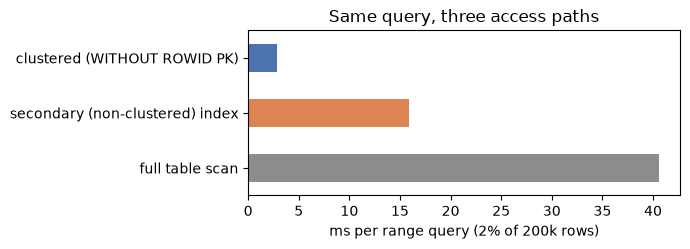

In [23]:
con.execute('DROP INDEX idx_cust_amount')                      # make sure the range query cannot be answered from an index alone
con.execute("""CREATE TABLE orders_by_cust(customer_id INT, id INT, amount REAL, quantity INT, status TEXT, created TEXT,
                                           PRIMARY KEY (customer_id, id)) WITHOUT ROWID""")
con.execute('INSERT INTO orders_by_cust SELECT customer_id, id, amount, quantity, status, created FROM orders')
q_range = 'SELECT SUM(quantity), COUNT(*) FROM {t} WHERE customer_id BETWEEN ? AND ?'
ranges = [(int(lo), int(lo) + 400) for lo in rng.integers(1, 19_000, 20)]      # each range is about 2% of the rows
for tname in ['orders', 'orders_by_cust']:
    print(f'{tname:15}', plan(q_range.format(t=tname), ranges[0]))
assert all(con.execute(q_range.format(t='orders'), r).fetchone() == con.execute(q_range.format(t='orders_by_cust'), r).fetchone()
           for r in ranges)
t_sec = bench(q_range.format(t='orders'), ranges)
t_clu = bench(q_range.format(t='orders_by_cust'), ranges)
t_scan = bench(q_range.format(t='orders NOT INDEXED'), ranges)
res = pd.Series({'full table scan': t_scan, 'secondary (non-clustered) index': t_sec, 'clustered (WITHOUT ROWID PK)': t_clu})
print(res.round(3).to_string()); print(f'clustered is {t_sec / t_clu:.1f}x faster than the non-clustered index here')
ax = res.plot.barh(figsize=(7, 2.6), color=['#8C8C8C', '#DD8452', '#4C72B0'])
ax.set_xlabel('ms per range query (2% of 200k rows)'); ax.set_title('Same query, three access paths')
plt.tight_layout(); plt.show()

**What just happened?** Both tables return identical results (asserted). The clustered layout answered the range query fastest because the
matching rows sit together in consecutive B-tree leaves. The non-clustered index found the matching row ids quickly but then needed one
random table lookup per row, and the full scan had to read all 200,000 rows. (Everything here is in memory; on a real disk, where a random
read costs far more than a sequential one, the gaps are much larger.)

> 🎓 **Interview tip.** "Why is a range query on a clustered index faster than on a secondary index?" Because k matching rows cost about
> k / bfr sequential block reads with clustering but up to k random block reads without it.

---
## 9. When indexes hurt

> **In plain English:** indexes slow down every write, and when a query wants most of the table, simply reading the whole table is faster.

Indexes are not free:
1. **Every write pays**: an `INSERT` must also insert into every index B-tree; an `UPDATE` of an indexed column moves entries; a `DELETE` removes them.
2. **Space**: each index is another B-tree, often a large fraction of the table's size.
3. **Low selectivity**: if a predicate matches a large fraction of rows, following the index (one random lookup per row) is **slower** than
   scanning the table sequentially. Optimizers estimate the **selectivity** (fraction of rows matching) to decide (notebook 08).

In [24]:
def insert_cost(n_indexes, n=60_000):
    c = sqlite3.connect(':memory:')
    c.execute('CREATE TABLE t(id INTEGER PRIMARY KEY, a INT, b REAL, c TEXT, d INT)')
    for col in ['a', 'b', 'c', 'd'][:n_indexes]:
        c.execute(f'CREATE INDEX idx_{col} ON t({col})')
    r = np.random.default_rng(1)
    rows = list(zip(r.integers(0, 10**6, n).tolist(), r.random(n).tolist(),
                    [f'name{x}' for x in r.integers(0, 10**6, n)], r.integers(0, 100, n).tolist()))
    best = math.inf
    for _ in range(3):                                   # best of 3 runs
        c.execute('DELETE FROM t')
        t0 = time.perf_counter()
        c.executemany('INSERT INTO t(a, b, c, d) VALUES (?,?,?,?)', rows); c.commit()
        best = min(best, time.perf_counter() - t0)
    c.close()
    return best

ins = pd.Series({k: insert_cost(k) for k in range(5)})
print((ins * 1000).round(1).rename('ms to insert 60,000 rows').to_string())
print(f'4 indexes make inserts {ins[4] / ins[0]:.1f}x slower than no index')
assert ins[4] > ins[0]

0    322.1
1    481.1
2    852.9
3    786.3
4    823.5
4 indexes make inserts 2.6x slower than no index


plan with index : ['SEARCH orders USING INDEX idx_amount (amount<?)']
plan without    : ['SCAN orders']
 selectivity  index_ms  scan_ms
        0.00      0.26    54.28
        0.01      3.03    28.26
        0.05     31.57    57.42
        0.10     28.82    61.05
        0.20     72.75    31.84
        0.35    102.18    37.79
        0.50    156.94    40.82
        0.75    482.69    42.63
        1.00    481.54    46.33
index becomes slower than a full scan from selectivity 0.2


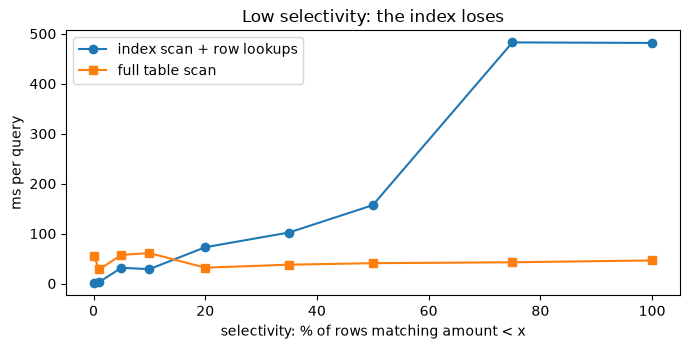

In [25]:
# Selectivity: index scan vs. full scan for "amount < x" as x grows
con.execute('CREATE INDEX idx_amount ON orders(amount)')
amounts = np.sort(orders.amount.to_numpy())
sels = [0.001, 0.01, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0]
rows = []
for s in sels:
    x = float(amounts[min(int(s * N_ORD), N_ORD - 1)]) + 0.001
    q_idx = 'SELECT SUM(quantity) FROM orders INDEXED BY idx_amount WHERE amount < ?'
    q_scan = 'SELECT SUM(quantity) FROM orders NOT INDEXED WHERE amount < ?'
    assert con.execute(q_idx, (x,)).fetchone() == con.execute(q_scan, (x,)).fetchone()
    rows.append(dict(selectivity=s, index_ms=bench(q_idx, [(x,)], repeat=3), scan_ms=bench(q_scan, [(x,)], repeat=3)))
sel_df = pd.DataFrame(rows)
print('plan with index :', plan('SELECT SUM(quantity) FROM orders INDEXED BY idx_amount WHERE amount < ?', (1.0,)))
print('plan without    :', plan('SELECT SUM(quantity) FROM orders NOT INDEXED WHERE amount < ?', (1.0,)))
print(sel_df.round(2).to_string(index=False))
cross = sel_df[sel_df.index_ms > sel_df.scan_ms].selectivity.min()
print('index becomes slower than a full scan from selectivity', cross)

plt.figure(figsize=(7, 3.6))
plt.plot(sel_df.selectivity * 100, sel_df.index_ms, marker='o', label='index scan + row lookups')
plt.plot(sel_df.selectivity * 100, sel_df.scan_ms, marker='s', label='full table scan')
plt.xlabel('selectivity: % of rows matching amount < x'); plt.ylabel('ms per query')
plt.title('Low selectivity: the index loses'); plt.legend(); plt.tight_layout(); plt.show()

**What just happened?**
- Inserting rows gets slower as indexes are added (compare 0 and 4 indexes above; single timings are noisy on a busy machine, but the trend is
  clear): every index is another B-tree to update on every insert.
- For very selective predicates (0.1% to 1% of rows) the index is far faster than a scan. The scan's cost is flat (it always reads every row),
  while the index's cost grows linearly with the number of matches because each one needs a lookup into the table. Past the crossover
  printed above, the index is the **slower** plan. Real optimizers use statistics to pick the cheaper side of this crossover; on a spinning
  disk, with random reads around 100x dearer than sequential ones, the crossover comes at a much lower selectivity (often just a few percent).

**Rules of thumb**
- Index columns used in selective `WHERE`, `JOIN ... ON`, `ORDER BY` / `GROUP BY` clauses; make hot queries **covering**.
- Do not index tiny tables, very low-cardinality columns (on their own), or columns of write-heavy tables nobody filters on.
- Composite index column order: equality columns first, then the range column; respect the leftmost prefix.
- Check with `EXPLAIN QUERY PLAN` (or `EXPLAIN ANALYZE` in PostgreSQL) instead of guessing.

> ⚠️ **Common mistake.** Wrapping an indexed column in a function, e.g. `WHERE substr(created, 1, 4) = '2025'`, makes the index unusable
> (the predicate is not **sargable**). Write a range on the raw column instead: `created >= '2025' AND created < '2026'`. Notebook 08 shows this.

In [26]:
con.execute('CREATE INDEX idx_created ON orders(created)')
print('function on the column :', plan("SELECT COUNT(*) FROM orders WHERE substr(created, 1, 4) = '2025'"))
print('range on the raw column:', plan("SELECT COUNT(*) FROM orders WHERE created >= '2025' AND created < '2026'"))
assert con.execute("SELECT COUNT(*) FROM orders WHERE substr(created, 1, 4) = '2025'").fetchone() == \
       con.execute("SELECT COUNT(*) FROM orders WHERE created >= '2025' AND created < '2026'").fetchone()

function on the column : ['SCAN orders USING COVERING INDEX idx_created']
range on the raw column: ['SEARCH orders USING COVERING INDEX idx_created (created>? AND created<?)']


---
## 10. 🔗 How this connects to modern AI

> **In plain English:** embeddings need their own kinds of indexes, but the ideas (posting lists, trees, bitmaps) carry straight over.

- **Vector indexes are the "B+ trees of embeddings".** A B+ tree needs a total order on keys; similarity search over 768-dimensional embeddings has no
  such order, so vector databases use different index families: **IVF** (inverted file: cluster the vectors, keep a posting list per cluster, the same
  idea as section 7), **HNSW** (navigable small-world graphs) and **product quantization**. They trade exactness for speed (approximate nearest neighbour).
  Continue with [`../03_vector_db/01_vector_databases.ipynb`](../03_vector_db/01_vector_databases.ipynb).
- **Hybrid search in RAG** combines a BM25 inverted index with a vector index: see
  [`../../08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb`](../../08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb) and
  [`../../07_NLP/13_industry_semantic_search_engine.ipynb`](../../07_NLP/13_industry_semantic_search_engine.ipynb).
- **Feature stores** serve online features by entity id from key-value stores built on B+ trees or LSM trees; point lookups must take milliseconds:
  [`../../15_MLOps/12_feature_stores.ipynb`](../../15_MLOps/12_feature_stores.ipynb).
- **Metadata filtering** in vector databases ("only documents from 2025 in the legal department") uses bitmap indexes, often Roaring bitmaps.
- **LSM trees** (log-structured merge trees: RocksDB, Cassandra, many vector and time-series stores) are the write-optimized alternative to B+ trees:
  they buffer writes in memory and merge sorted runs in the background, avoiding the write penalty you saw in section 9.
- **Learned indexes** (Kraska et al., 2018) replace a B+ tree's inner nodes with a small model that predicts a key's position in a sorted array: indexing as regression.

---
## 11. Recap

> **In plain English:** the whole notebook on one page.

- Cost is counted in **block reads**: scan b/2, binary search log₂ b, multi-level index ≈ log_fanout b.
- **Primary/clustering** index: file sorted on the key, can be **sparse**; **secondary** index: must be **dense**; at most one clustered index per table.
- **B+ tree**: balanced, high fan-out, data only in leaves, leaves linked. Insert splits (copy up from leaves, move up from internal nodes),
  delete borrows or merges; grows and shrinks **at the root**.
- Order from block size: n = ⌊(B + K)/(P + K)⌋; height ≈ log_fanout N, so 3 to 4 levels for billions of keys.
- **Hashing**: ~1 I/O equality lookups, no range queries. Static hashing degrades with overflow chains; **extendible** hashing doubles a directory
  (global/local depth); **linear** hashing splits round-robin without a directory.
- **Bitmap indexes**: bit vectors for low-cardinality columns, fast AND/OR/COUNT, poor for updates.
- **Inverted indexes**: term → postings; AND = sorted-list intersection; BM25 ranks results; the base of search engines and hybrid RAG.
- In SQLite: rowid tables are clustered; `CREATE INDEX` makes secondary B-trees; **covering** indexes avoid table lookups; check plans with `EXPLAIN QUERY PLAN`.
- Indexes **hurt** writes and lose to full scans at **low selectivity**.

## Practice problems

**1. (Easy)** Why can a sparse index only be built on the attribute the file is sorted on?

<details><summary>Show solution</summary>

A sparse index stores only some keys (e.g. the first key of each block) and relies on "the record with key k is in the block whose first key is the
largest one ≤ k". That is only true if the records are stored in key order. For any other attribute, a value could be in any block, so every value needs its own entry (dense).
</details>

**2. (Easy)** A table has 1,000,000 rows; a query matches 5,000 of them, 50 rows fit in a block. Estimate the block reads using (a) a clustered index,
(b) a non-clustered index, (c) a full scan, ignoring the index levels.

<details><summary>Show solution</summary>

(a) 5,000 / 50 = **100** blocks (matching rows are adjacent). (b) up to **5,000** blocks (one per row, in the worst case each in a different block).
(c) 1,000,000 / 50 = **20,000** blocks. The non-clustered index still wins here (selectivity 0.5%), but at 10% selectivity it would need up to
100,000 reads versus 20,000 for the scan.
</details>

**3. (Medium)** Blocks are 8 KB (8,192 bytes), keys are 16 bytes, child and record pointers 8 bytes. Compute the order n of internal nodes, the leaf capacity,
and the maximum number of levels for 100 million keys.

<details><summary>Show solution</summary>

n = ⌊(8192 + 16)/(8 + 16)⌋ = **342**. Leaf capacity = ⌊(8192 − 8)/(16 + 8)⌋ = **341**.
`height_bounds(10**8, 342)` gives **(4, 4)**: exactly 4 levels, whether the nodes are full or only half full.
</details>

**4. (Medium)** Insert 1, 2, 3, ..., 10 in increasing order into an empty B+ tree of order n = 4 (max 3 keys per leaf). Draw the final tree.
What do you notice about the leaves?

<details><summary>Show solution</summary>

`build(range(1, 11))` produces root **[7]**, internal nodes **[3 5] [9]** and leaves **[1 2] [3 4] [5 6] [7 8] [9 10]**.
Every leaf except possibly the last is only at the minimum fill (2 of 3): sorted inserts always split the rightmost leaf and leave the left half
behind. This is why databases bulk-load sorted data bottom-up instead.
</details>

**5. (Medium)** Using extendible hashing with h(k) = k, bucket capacity 2 and the last bits of h, insert 1, 3, 5, 7. What is the final global depth, and why
is this a bad case?

<details><summary>Show solution</summary>

1, 3, 5, 7 are 001, 011, 101, 111: all odd, and 3 and 7 share the last **two** bits (11), 1 and 5 share 01. Inserting 5 into the full bucket {1, 3}
doubles the directory (g = 1): all odd → same bucket again → double again (g = 2): {1, 5} and {3}. Inserting 7 goes to {3, 7}, which still fits.
Final **global depth 2**. Keys that agree on many low bits force repeated doubling; that is why a good hash function that scrambles bits is essential.
</details>

**6. (Medium)** Why are bitmap indexes common in data warehouses but rare in OLTP databases?

<details><summary>Show solution</summary>

Warehouses are read-mostly, with ad-hoc queries combining many low-cardinality predicates and counts; bitmaps answer those with fast bitwise AND/OR and
compress well. OLTP workloads update rows constantly; updating a compressed bitmap is expensive and locking it would block many rows at once.
</details>

**7. (Coding)** Add a method `count_range(lo, hi)` to `BPlusTree` that counts keys in [lo, hi] using the leaf chain, and test it against a sorted list.

<details><summary>Show solution</summary>

```python
def count_range(self, lo, hi):
    return len(self.range(lo, hi))
BPlusTree.count_range = count_range

tr = build(random.Random(9).sample(range(1000), 300), n=5)
srt = sorted(k for l in tr.levels()[-1] for k in l.keys)
assert tr.count_range(100, 400) == len([k for k in srt if 100 <= k <= 400])
```
A real system can do better by storing subtree counts in internal nodes (an "order-statistic" or counted B-tree) to answer counts in O(log N).
</details>

**8. (Hard, coding)** Implement `intersect_many(lists)` for k sorted postings lists that always advances the pointer of the list with the smallest
current value (no Python sets), and check it against set intersection on random lists.

<details><summary>Show solution</summary>

```python
def intersect_many(lists):
    idx, out = [0] * len(lists), []
    while all(i < len(l) for i, l in zip(idx, lists)):
        cur = [l[i] for i, l in zip(idx, lists)]
        if min(cur) == max(cur):
            out.append(cur[0]); idx = [i + 1 for i in idx]
        else:
            j = cur.index(min(cur)); idx[j] += 1
    return out

r = random.Random(4)
for _ in range(200):
    ls = [sorted(r.sample(range(60), r.randint(0, 40))) for _ in range(r.randint(1, 4))]
    assert intersect_many(ls) == sorted(set(ls[0]).intersection(*ls[1:]))
```
</details>

In [27]:
# Verify the practice solutions
assert internal_order(8192, 16, 8) == 342 and leaf_capacity(8192, 16, 8, 8) == 341
assert height_bounds(10**8, 342) == (4, 4)
t4 = build(range(1, 11))
print('problem 4:', str(t4).replace(chr(10), '  //  '))
assert str(t4) == '[7]\n[3 5]  [9]\n[1 2]  [3 4]  [5 6]  [7 8]  [9 10]'
e5 = ExtendibleHash(capacity=2)
for k in [1, 3, 5, 7]: e5.put(k)
assert e5.global_depth == 2

def count_range(self, lo, hi):
    return len(self.range(lo, hi))
BPlusTree.count_range = count_range
tr = build(random.Random(9).sample(range(1000), 300), n=5)
srt = sorted(k for l in tr.levels()[-1] for k in l.keys)
assert tr.count_range(100, 400) == len([k for k in srt if 100 <= k <= 400])

def intersect_many(lists):
    idx, out = [0] * len(lists), []
    while all(i < len(l) for i, l in zip(idx, lists)):
        cur = [l[i] for i, l in zip(idx, lists)]
        if min(cur) == max(cur):
            out.append(cur[0]); idx = [i + 1 for i in idx]
        else:
            j = cur.index(min(cur)); idx[j] += 1
    return out
r = random.Random(4)
for _ in range(200):
    ls = [sorted(r.sample(range(60), r.randint(0, 40))) for _ in range(r.randint(1, 4))]
    assert intersect_many(ls) == sorted(set(ls[0]).intersection(*ls[1:]))
con.close()
print('practice solutions verified')

problem 4: [7]  //  [3 5]  [9]  //  [1 2]  [3 4]  [5 6]  [7 8]  [9 10]


practice solutions verified


## Further reading
- Silberschatz, Korth & Sudarshan, *Database System Concepts*, 7th ed., ch. 14 (Indexing: B+ trees, hashing, bitmap indexes, write-optimized indexes).
- Elmasri & Navathe, *Fundamentals of Database Systems*, 7th ed., ch. 16 (hashing) and ch. 17 (Indexing Structures for Files and Physical Database Design).
- Ramakrishnan & Gehrke, *Database Management Systems*, 3rd ed., ch. 10 (Tree-Structured Indexing) and ch. 11 (Hash-Based Indexing).
- Manning, Raghavan & Schütze, *Introduction to Information Retrieval* (free online), ch. 1–2 (inverted indexes) and ch. 11 (BM25).
- Free: CMU 15-445/645 lectures on B+ trees and hash tables; the SQLite "Query Planning" document (sqlite.org/queryplanner.html);
  GeeksforGeeks DBMS tutorial, indexing section: https://www.geeksforgeeks.org/dbms/

## Next notebook
[`08_query_processing_and_optimization.ipynb`](08_query_processing_and_optimization.ipynb): how the DBMS turns SQL into a plan, implements joins and sorting with these structures, and picks the cheapest plan.